# 02. Baseline Models

**Goal:** build simple forecasts that every later model (Holt-Winters, ARIMA) has to beat.

A baseline is a forecast with almost no maths, for example "tomorrow will look like the same weekday last week". If a complicated model cannot beat it, the complicated model is not worth using.

**Input:** `data/processed/daily_sales.csv` (made by notebook 01).

**Two ways to test each method**
1. **One day ahead:** forecast tomorrow from everything up to today.
2. **30 days ahead:** forecast the next 30 days from one fixed point in time. This is the real planning question, and it is harder.

For the 30-day test we repeat it from many starting points ("rolling origin") instead of trusting a single window.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 13})
BROWN, RED, GREEN, GREY = "#6F4E37", "#C1272D", "#2A7F62", "#8A8A8A"

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIG, TAB = ROOT / "outputs" / "figures", ROOT / "outputs" / "tables"
for p in (FIG, TAB):
    p.mkdir(parents=True, exist_ok=True)

def save_fig(name):
    plt.savefig(FIG / name, bbox_inches="tight")
    plt.show()

daily = pd.read_csv(ROOT / "data" / "processed" / "daily_sales.csv", parse_dates=["date"], index_col="date")
y = daily["revenue"].where(daily["reported"])          # days with no data become NaN, not 0
print(f"{len(y)} days, {int(y.isna().sum())} without data")
y.tail()

388 days, 7 without data


date
2025-03-19    623.56
2025-03-20    597.60
2025-03-21    636.80
2025-03-22    365.42
2025-03-23    204.76
Name: revenue, dtype: float64

## 1. Accuracy measures

| Measure | Meaning | Note |
|---|---|---|
| MAE | average miss per day, in revenue units | easy to read |
| RMSE | like MAE but punishes big misses | |
| WAPE | total absolute error / total actual revenue | steady, good for comparing |
| SMAPE | percentage error | **explodes on very low-sales days**, use with care |
| Bias | average (forecast - actual) | positive = forecasts too high |

Days with no data are left out of every measure.

In [2]:
def metrics(actual, forecast):
    a, f = np.asarray(actual, float), np.asarray(forecast, float)
    ok = ~np.isnan(a) & ~np.isnan(f)
    a, f = a[ok], f[ok]
    return {
        "MAE": np.mean(np.abs(a - f)),
        "RMSE": np.sqrt(np.mean((a - f) ** 2)),
        "WAPE": np.sum(np.abs(a - f)) / np.sum(a),
        "SMAPE": np.mean(2 * np.abs(a - f) / (np.abs(a) + np.abs(f))),
        "Bias": np.mean(f - a),
        "n_days": int(ok.sum()),
    }

## 2. The baseline forecasters

Each function sees **only the history** up to the forecast start and returns forecasts for the next `h` days.

| Name | Idea |
|---|---|
| `naive_last` | repeat the last known day |
| `seasonal_naive` | same weekday last week |
| `weekday_avg_2w / 4w / 8w` | average of the same weekday over the last 2, 4 or 8 weeks |
| `mean_7d` | flat forecast = average of the last 7 days |
| `mean_28d` | flat forecast = average of the last 28 days |
| `level_x_weekday` | 28-day average times a weekday index learned from the last 8 weeks |

In [3]:
def _same_weekday_values(hist, target_date, weeks):
    # values of the same weekday in the previous `weeks` weeks, counted back from the end of history
    last = hist.index[-1]
    vals = []
    for k in range(1, weeks + 1):
        # find the most recent date <= last that has the target weekday, then go back k-1 more weeks
        back = (last.weekday() - target_date.weekday()) % 7
        d = last - pd.Timedelta(days=back + 7 * (k - 1))
        if d in hist.index:
            vals.append(hist.loc[d])
    return np.array(vals, float)

def naive_last(hist, dates):
    v = hist.dropna()
    return np.full(len(dates), v.iloc[-1])

def seasonal_naive(hist, dates):
    out = []
    for t in dates:
        v = _same_weekday_values(hist, t, 6)
        v = v[~np.isnan(v)]
        out.append(v[0] if len(v) else hist.mean())   # most recent available same weekday
    return np.array(out)

def make_weekday_avg(weeks):
    def f(hist, dates):
        out = []
        for t in dates:
            v = _same_weekday_values(hist, t, weeks)
            out.append(np.nanmean(v) if np.any(~np.isnan(v)) else hist.mean())
        return np.array(out)
    return f

def mean_last(n):
    def f(hist, dates):
        return np.full(len(dates), hist.iloc[-n:].mean())
    return f

def level_x_weekday(hist, dates):
    seg = hist.iloc[-56:]
    idx = seg.groupby(seg.index.weekday).mean()
    idx = idx / idx.mean()
    level = hist.iloc[-28:].mean()
    return np.array([level * idx[t.weekday()] for t in dates])

MODELS = {
    "naive_last": naive_last,
    "seasonal_naive": seasonal_naive,
    "weekday_avg_2w": make_weekday_avg(2),
    "weekday_avg_4w": make_weekday_avg(4),
    "weekday_avg_8w": make_weekday_avg(8),
    "mean_7d": mean_last(7),
    "mean_28d": mean_last(28),
    "level_x_weekday": level_x_weekday,
}
list(MODELS)

['naive_last',
 'seasonal_naive',
 'weekday_avg_2w',
 'weekday_avg_4w',
 'weekday_avg_8w',
 'mean_7d',
 'mean_28d',
 'level_x_weekday']

## 3. Test 1: one day ahead

For every day from day 120 onwards, forecast it using only earlier days. (The first 120 days are kept as warm-up history.)

In [4]:
START = 120
rows = []
for name, fn in MODELS.items():
    preds = [fn(y.iloc[:i], [y.index[i]])[0] for i in range(START, len(y))]
    rows.append({"model": name, **metrics(y.iloc[START:], preds)})
one_day = pd.DataFrame(rows).set_index("model").sort_values("MAE")
one_day.round(3)

,MAE,RMSE,WAPE,SMAPE,Bias,n_days
model,,,,,,
mean_7d,121.423,153.504,0.376,0.418,-4.415,264
level_x_weekday,121.968,156.698,0.378,0.422,-14.251,264
weekday_avg_4w,125.204,163.738,0.388,0.436,-14.352,264
mean_28d,126.349,159.547,0.391,0.430,-11.042,264
weekday_avg_2w,131.131,168.825,0.406,0.464,-9.551,264
weekday_avg_8w,134.763,169.693,0.417,0.453,-21.502,264
seasonal_naive,149.057,189.479,0.462,0.532,-8.260,264
naive_last,157.736,200.080,0.488,0.533,-0.173,264


## 4. Test 2: 30 days ahead with rolling origins

From each starting point we forecast the next 30 days using only earlier data, then slide the starting point forward 7 days and repeat.

The very last window (the final 30 days) is also shown separately. It is the same test used in the Excel workbook.

In [5]:
H = 30
origins = list(range(START, len(y) - H + 1, 7))
print(f"{len(origins)} rolling origins, from {y.index[origins[0]].date()} to {y.index[origins[-1]].date()}")

records = []     # one row per (model, origin, horizon day)
for name, fn in MODELS.items():
    for o in origins:
        dates = y.index[o:o + H]
        fc = fn(y.iloc[:o], dates)
        for h, (d, f_, a_) in enumerate(zip(dates, fc, y.iloc[o:o + H]), 1):
            records.append((name, o, h, d, f_, a_))
bt = pd.DataFrame(records, columns=["model", "origin", "h", "date", "forecast", "actual"])

def summarise(frame):
    return pd.DataFrame({m: metrics(g["actual"], g["forecast"]) for m, g in frame.groupby("model")}).T

all_origins = summarise(bt).sort_values("MAE")
last_window = summarise(bt[bt["origin"] == origins[-1]]).sort_values("MAE")
print("All rolling origins pooled:")
display(all_origins.round(3))
print("Last 30 days only (same window as the Excel backtest):")
display(last_window.round(3))

35 rolling origins, from 2024-06-29 to 2025-02-22
All rolling origins pooled:


,MAE,RMSE,WAPE,SMAPE,Bias,n_days
mean_7d,139.768,178.700,0.435,0.477,-17.140,1033.0
level_x_weekday,140.385,178.520,0.437,0.471,-26.225,1033.0
mean_28d,140.976,178.145,0.439,0.471,-25.537,1033.0
weekday_avg_4w,141.965,180.748,0.442,0.480,-27.232,1033.0
weekday_avg_8w,144.223,182.068,0.449,0.478,-27.423,1033.0
weekday_avg_2w,147.796,187.868,0.460,0.512,-21.978,1033.0
naive_last,157.209,202.936,0.490,0.520,-11.804,1033.0
seasonal_naive,163.769,207.392,0.510,0.575,-18.493,1033.0


Last 30 days only (same window as the Excel backtest):


,MAE,RMSE,WAPE,SMAPE,Bias,n_days
weekday_avg_4w,76.339,98.097,0.175,0.181,-33.118,30.0
weekday_avg_2w,83.536,96.996,0.192,0.218,29.666,30.0
level_x_weekday,100.268,118.596,0.230,0.245,-29.353,30.0
seasonal_naive,101.383,118.743,0.233,0.257,74.471,30.0
weekday_avg_8w,127.366,165.819,0.292,0.292,-108.046,30.0
mean_28d,162.778,183.806,0.373,0.404,-20.902,30.0
mean_7d,167.165,203.276,0.383,0.403,89.294,30.0
naive_last,264.413,316.949,0.606,0.534,259.054,30.0


In [6]:
# Cross-check with the Excel workbook (Backtest sheet): MAE 101.4 seasonal naive, 76.3 weekday average (4 weeks), 167.2 moving average (7 days)
print({k: round(last_window.loc[k, "MAE"], 1) for k in ["seasonal_naive", "weekday_avg_4w", "mean_7d"]})

{'seasonal_naive': np.float64(101.4), 'weekday_avg_4w': np.float64(76.3), 'mean_7d': np.float64(167.2)}


**Cross-check:** these three numbers should match the Excel backtest (101.4, 76.3 and 167.2). They do, so the Python and Excel workings agree.

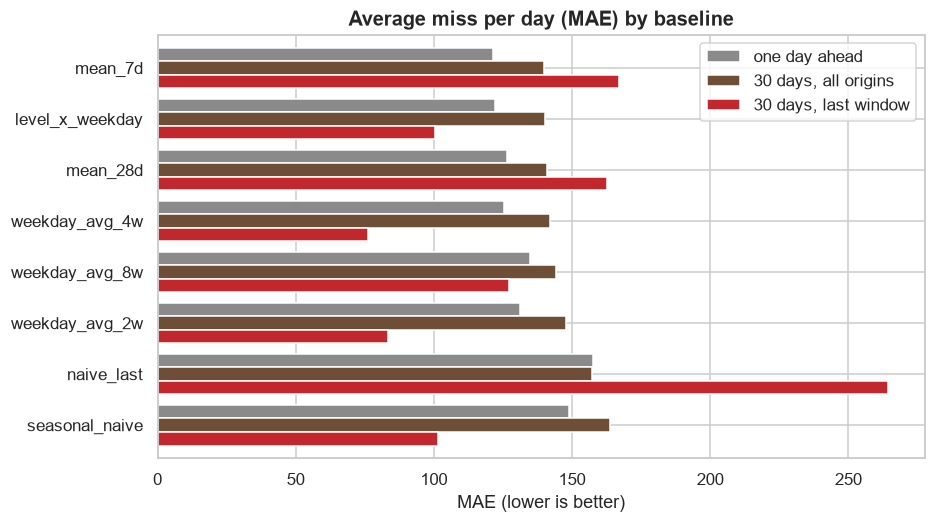

In [7]:
cmp = pd.DataFrame({
    "one day ahead": one_day["MAE"],
    "30 days, all origins": all_origins["MAE"],
    "30 days, last window": last_window["MAE"],
}).sort_values("30 days, all origins")

ax = cmp.plot.barh(figsize=(9, 5), color=[GREY, BROWN, RED], width=.8)
ax.invert_yaxis()
ax.set(title="Average miss per day (MAE) by baseline", xlabel="MAE (lower is better)", ylabel="")
save_fig("08_baseline_mae.png")

## 5. How the error grows with the forecast horizon

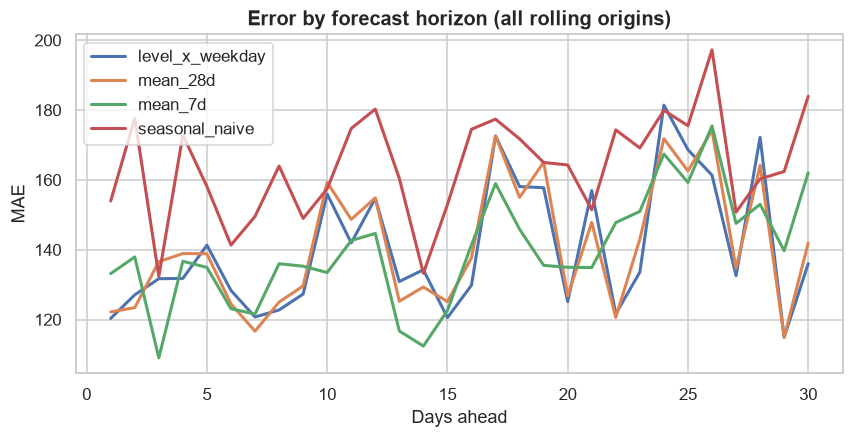

In [8]:
top = all_origins.index[:3].tolist()
by_h = (bt[bt["model"].isin(top + ["seasonal_naive"])]
        .assign(abs_err=lambda t: (t["actual"] - t["forecast"]).abs())
        .groupby(["model", "h"])["abs_err"].mean().unstack(0))

fig, ax = plt.subplots(figsize=(9, 4))
for m in by_h.columns:
    ax.plot(by_h.index, by_h[m], label=m, lw=2)
ax.set(title="Error by forecast horizon (all rolling origins)", xlabel="Days ahead", ylabel="MAE")
ax.legend()
save_fig("09_error_by_horizon.png")

## 6. Last 30 days: actual vs baselines

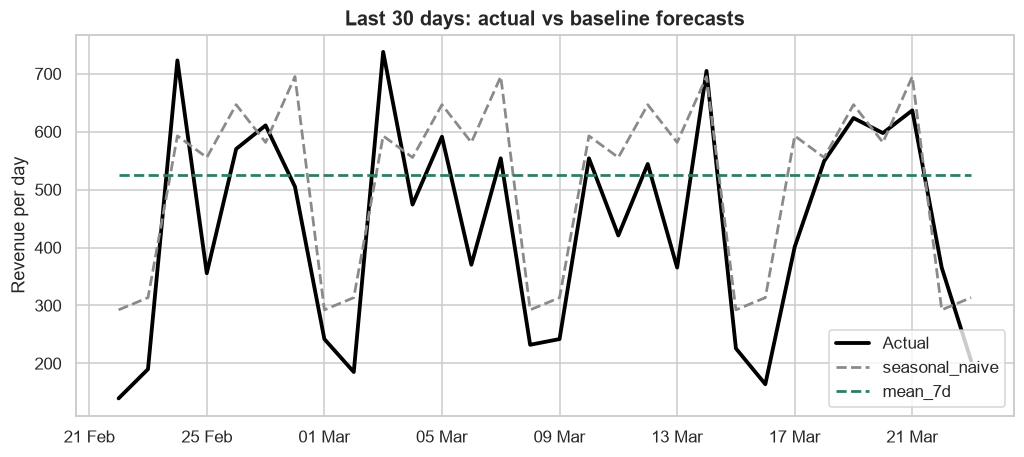

In [9]:
lw = bt[bt["origin"] == origins[-1]]
show = ["seasonal_naive", all_origins.index[0], "mean_7d"]
show = list(dict.fromkeys(show))

fig, ax = plt.subplots(figsize=(11, 4.5))
act = lw[lw["model"] == show[0]]
ax.plot(act["date"], act["actual"], color="black", lw=2.5, label="Actual")
for m, c in zip(show, [GREY, GREEN, RED]):
    g = lw[lw["model"] == m]
    ax.plot(g["date"], g["forecast"], ls="--", lw=1.8, color=c, label=m)
ax.set(title="Last 30 days: actual vs baseline forecasts", ylabel="Revenue per day")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
ax.legend()
save_fig("10_last_window.png")

## 7. Save results and findings

In [10]:
one_day.round(4).to_csv(TAB / "baseline_one_day_ahead.csv")
all_origins.round(4).to_csv(TAB / "baseline_30day_all_origins.csv")
last_window.round(4).to_csv(TAB / "baseline_30day_last_window.csv")

best_all, best_last, best_1d = all_origins.index[0], last_window.index[0], one_day.index[0]
print(f"1. One day ahead the best baseline is {best_1d} (MAE {one_day.loc[best_1d, 'MAE']:.1f}).")
print(f"2. 30 days ahead, over {len(origins)} rolling origins, the best baseline is {best_all} "
      f"(MAE {all_origins.loc[best_all, 'MAE']:.1f}, WAPE {all_origins.loc[best_all, 'WAPE']:.0%}).")
print(f"3. In the last 30 days alone the best is {best_last} (MAE {last_window.loc[best_last, 'MAE']:.1f}).")
print(f"4. Worst baseline over 30 days: {all_origins.index[-1]} (MAE {all_origins.iloc[-1]['MAE']:.1f}).")
gap = all_origins["MAE"].iloc[3] / all_origins["MAE"].iloc[0] - 1
print(f"5. Over all origins the top four baselines are within {gap:.0%} of each other, so no baseline is clearly best. "
      f"{best_last} wins only the last window, so one window can mislead.")
print(f"6. SMAPE ({all_origins.loc[best_all, 'SMAPE']:.0%}) is higher than WAPE ({all_origins.loc[best_all, 'WAPE']:.0%}) for the best baseline, "
      "because of low-sales days. Use WAPE and MAE for comparing.")
print("7. Models in notebooks 03 and 04 must beat these numbers, on the same rolling origins.")

1. One day ahead the best baseline is mean_7d (MAE 121.4).
2. 30 days ahead, over 35 rolling origins, the best baseline is mean_7d (MAE 139.8, WAPE 44%).
3. In the last 30 days alone the best is weekday_avg_4w (MAE 76.3).
4. Worst baseline over 30 days: seasonal_naive (MAE 163.8).
5. Over all origins the top four baselines are within 2% of each other, so no baseline is clearly best. weekday_avg_4w wins only the last window, so one window can mislead.
6. SMAPE (48%) is higher than WAPE (44%) for the best baseline, because of low-sales days. Use WAPE and MAE for comparing.
7. Models in notebooks 03 and 04 must beat these numbers, on the same rolling origins.


## Next

`03_holt_winters_and_arima.ipynb` fits Holt-Winters and ARIMA/SARIMA. In notebook 04 they are tested against these baselines on exactly the same rolling origins.